In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

In [2]:
def fetch_data(year):
    extraction_evo_path = f"s3://mateomorin/legifrance/extraction/contingent_evolution/year={year}/shards/"
    extraction_path = f"s3://mateomorin/legifrance/extraction_contingent/year={year}/extraction_{year}.parquet"
    metadata_path = f"s3://mateomorin/legifrance/metadata/acco_metadata_{year}.parquet"

    extraction_evo = []
    for file in fs.ls(extraction_evo_path):
        extraction_evo.append(pd.read_parquet(file, filesystem=fs))
    extraction_evo = pd.concat(extraction_evo)
    extraction = pd.read_parquet(extraction_path, filesystem=fs)
    metadata = pd.read_parquet(metadata_path, filesystem=fs)

    return extraction, extraction_evo, metadata

In [3]:
def treat_extraction(extraction, extraction_evo):
      print(f"Nombre d'erreurs dans extraction: {extraction['erreur'].count()}/{len(extraction)}")
      print(f"Nombre d'erreurs dans extraction_evo: {extraction_evo['erreur'].count()}/{len(extraction)}")
      extraction = extraction[pd.col("erreur").isna()]
      extraction_evo = extraction_evo[pd.col("erreur").isna()]

      compare_extraction = extraction_evo.merge(extraction, on="reference", how="inner", suffixes=["_evo", ""])

      mask_presence = pd.col("presence_contingent_conventionnel_evo") | pd.col("presence_contingent_conventionnel")
      compare_extraction = compare_extraction[mask_presence]

      mask_mismatch = pd.col("presence_contingent_conventionnel_evo") ^ pd.col("presence_contingent_conventionnel")
      mismatches = compare_extraction[mask_mismatch]

      print(f"Nombre de contingents mesurés dans extraction: {compare_extraction['presence_contingent_conventionnel'].sum()}")
      print(f"Nombre de contingents mesurés dans extraction_evo: {compare_extraction['presence_contingent_conventionnel_evo'].sum()}")
      print(f"Nombre d'observations différentes sur la présence d'un contingent: {len(mismatches)}")

      removed_other_text = mismatches.loc[pd.col("presence_contingent_conventionnel"), "reference"].to_list()

      removed_anon = mismatches[pd.col("presence_contingent_conventionnel_evo")]
      pattern = r"(?i)\b(?:" \
            r"cach[ée]e?|dissimul[ée]e?|laiss[ée]e?\s+blanche?|masqu[ée]e?|occult[ée]e?|effac[ée]e?|" \
            r"placeholder|tiret|n/a|na|none|null|unspecified|blank|" \
            r"non\s+sp[ée]cifi[ée]e?|non\s+mentionn[ée]e?|non\s+fourni[ée]e?|non\s+communiqu[ée]e?|non\s+trouv[ée]e?|non\s+disponible|non\s+pr[ée]cis[ée]e?|" \
            r"pas\s+de\s+donn[ée]e?s?|donn[ée]e?\s+manquante?|aucune?\s+information|information\s+absente|" \
            r"non\s+applicable|non\s+renseign[ée]e?|introuvable|inconnu[ee]?s?|" \
            r"pas\s+mentionn[ée]e?|pas\s+sp[ée]cifi[ée]e?" \
            r")\b"
      removed_anon = removed_anon[pd.col("justification_ou_reserve_evo").str.contains(pattern, na=False)]
      removed_anon = removed_anon["reference"].to_list()

      removed_recall = mismatches[pd.col("presence_contingent_conventionnel_evo")]
      removed_recall = removed_recall[pd.col("justification_ou_reserve").str.contains("rappel", na=False)]
      removed_recall = removed_recall["reference"].to_list()

      removed = list(set(removed_other_text + removed_anon + removed_recall))

      extraction_evo = extraction_evo[pd.col("presence_contingent_conventionnel")]
      extraction_filtered = extraction_evo[~pd.col("reference").isin(removed)]
      print(f"""{len(removed)} observations filtrées:
      - {len(removed_other_text)} fixent un accord tiré d'un autre texte légal
      - {len(removed_anon)} ont une donnée manquante qui a été interprétée comme présente par Qwen
      - {len(removed_recall)} rappellent un contingent sans le fixer dans l'accord
      """)

      citation_anon = mismatches[pd.col("reference").isin(removed_anon)]["citation_exacte_evo"].to_list()
      
      print("Citation des extraits supposés anonymisés :")
      for i, citation in enumerate(citation_anon, 1):
          print(f"{i}. {citation}")

      print("")
      print("Références anonymisées (dans le même ordre) :")
      for i, ref in enumerate(removed_anon, 1):
          print(f"{i}. {ref}")

      return extraction_filtered

In [4]:
def add_correct_references(extraction_filtered, extraction, references_to_add):
    new_references = set(references_to_add) - set(extraction_filtered["reference"].to_list())
    new_lines = extraction[pd.col("reference").isin(new_references)]

    return pd.concat([extraction_filtered, new_lines])

In [5]:
def develop_contingents(df):
    initial_len = len(df)
    print("Taille iniale :", initial_len)
    if initial_len == 0:
        return df
    df = df.copy()

    # Convert to correct dtype
    if isinstance(df["contingents"][0], str):
        contingents = df["contingents"].to_list()
        contingents = [json.loads(chaine) for chaine in contingents]
        df["contingents"] = contingents

    df = df.explode("contingents")
    df_dict = pd.json_normalize(df["contingents"])
    df = pd.concat([df.drop(columns=["contingents"]), df_dict], axis=1)
    print("Taille finale :", len(df))
    return df

In [6]:
def distrib_contingent(extraction_developped):
    # Contingent mensuel → annuel
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "nombre_heures_fixe"] *= 12
    extraction_developped.loc[pd.col("periode").str.contains("mensuel"), "periode"] = "anuelle (montant à chaque mois x 12)"

    # Définition des bornes de 50 à 600 avec un pas de 25
    bins = range(0, 625, 1)

    plt.figure(figsize=(10, 5))

    # Filtrage entre 50 et 600 h et tracé de l'histogramme
    data = extraction_developped.query("0 <= nombre_heures_fixe <= 600")["nombre_heures_fixe"]

    data.hist(
        bins=bins,
        color="#2b5c8f",
        grid=True,
    )

    plt.title("Répartition des contingents annuels d'heures supplémentaires", fontsize=13, fontweight="bold", pad=12)
    plt.xlabel("Nombre d'heures", labelpad=8)
    plt.ylabel("Nombre de contingents mentionnés", labelpad=8)
    plt.xticks(range(0, 625, 50))
    plt.yticks(range(50, 700, 50))
    plt.grid(alpha=0.5, linestyle="--")
    plt.tight_layout()
    plt.show()

In [7]:
def distrib_type_substitution(extraction_developped):
    data = extraction_developped["type_substitution"].value_counts().sort_values(ascending=True)

    _, ax = plt.subplots(figsize=(10, 5))

    # Personnalisation des barres
    bars = ax.barh(data.index, data.values, color="#3498db", height=0.6, alpha=0.85)

    # Ajout des valeurs exactes au bout de chaque barre
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 15, bar.get_y() + bar.get_height()/2, f'{int(width)}', 
                va='center', ha='left', fontsize=10, fontweight='bold', color='#2c3e50')

    # Esthétique générale
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#bdc3c7')
    ax.spines['bottom'].set_color('#bdc3c7')

    # Titre et labels
    ax.set_title("Répartition des types de substitution", fontsize=14, fontweight='bold', pad=20, loc='left', color='#2c3e50')
    ax.set_xlabel("Nombre d'occurrences", fontsize=11, color='#34495e', labelpad=10)

    # Grille légère en arrière-plan uniquement sur l'axe X
    ax.xaxis.grid(True, linestyle='--', alpha=0.5, color='#bdc3c7')
    ax.set_axisbelow(True)

    # Ajustement des marges
    plt.tight_layout()

# Affichage
plt.show()

## Résultats par année

### 2018

In [8]:
extraction, extraction_evo, metadata = fetch_data(2018)

In [9]:
extraction_filtered = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/2127
Nombre d'erreurs dans extraction_evo: 1/2127
Nombre de contingents mesurés dans extraction: 911
Nombre de contingents mesurés dans extraction_evo: 906
Nombre d'observations différentes sur la présence d'un contingent: 119
84 observations filtrées:
      - 62 fixent un accord tiré d'un autre texte légal
      - 3 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 19 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
1. Le contingent annuel d’heures supplémentaires pour le personnel sédentaire est maintenu à XXX heures de temps de travail effectif par année civile.
2. **Article 1/ Contingent annuel d’heures supplémentaires**
Le contingent annuel d’heures supplémentaires librement utilisable est fixé à XXXXXXXXXXXX heures.
3. Le contingent annuel d’heures supplémentaires fixé par la Convention collective de la Maintenance, distribution et location de matériels agricole

In [10]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 884
Taille finale : 910


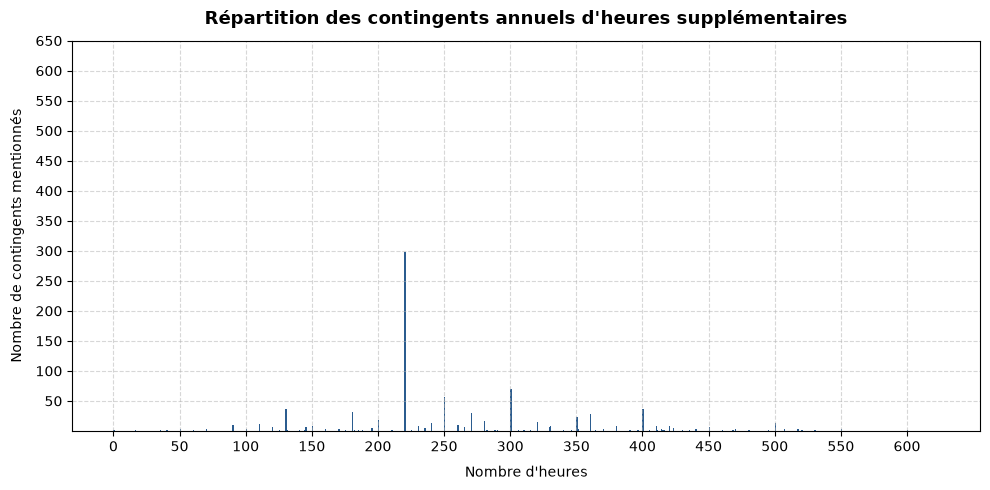

In [11]:
distrib_contingent(extraction_developped)

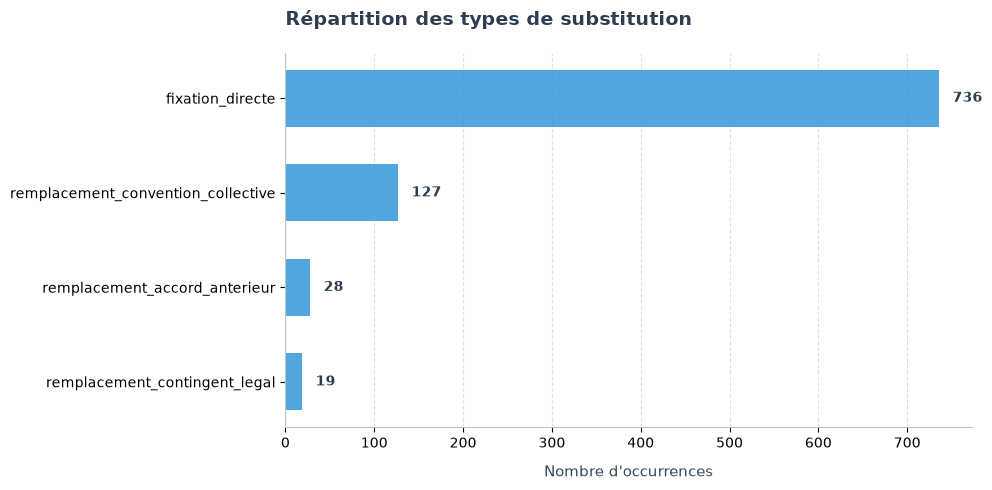

In [12]:
distrib_type_substitution(extraction_developped)

### 2019

In [13]:
extraction, extraction_evo, metadata = fetch_data(2019)

In [14]:
extraction_filtered = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3056
Nombre d'erreurs dans extraction_evo: 1/3056
Nombre de contingents mesurés dans extraction: 1723
Nombre de contingents mesurés dans extraction_evo: 1725
Nombre d'observations différentes sur la présence d'un contingent: 144
92 observations filtrées:
      - 71 fixent un accord tiré d'un autre texte légal
      - 4 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 17 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
1. Le contingent d’heures supplémentaires est fixé à XXX heures par salarié et par année civile du 1er janvier au 31 décembre.
2. Le contingent d’heures supplémentaires sera désormais fixé à heures par année civile et par salarié. D’un commun accord entre les parties, il a été expressément convenu que ce nouveau contingent sera applicable à l’année 2019 qui est en cours
3. Par dérogation à l'article 9.1.3.2 de la CCN des laboratoires extra-hospitaliers 

In [15]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, ["T09119003383"])

In [16]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1705
Taille finale : 1750


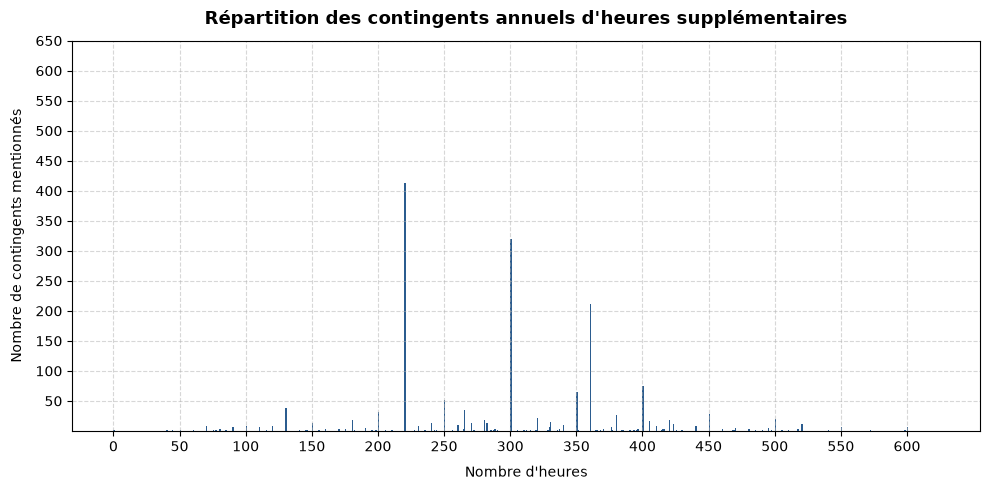

In [17]:
distrib_contingent(extraction_developped)

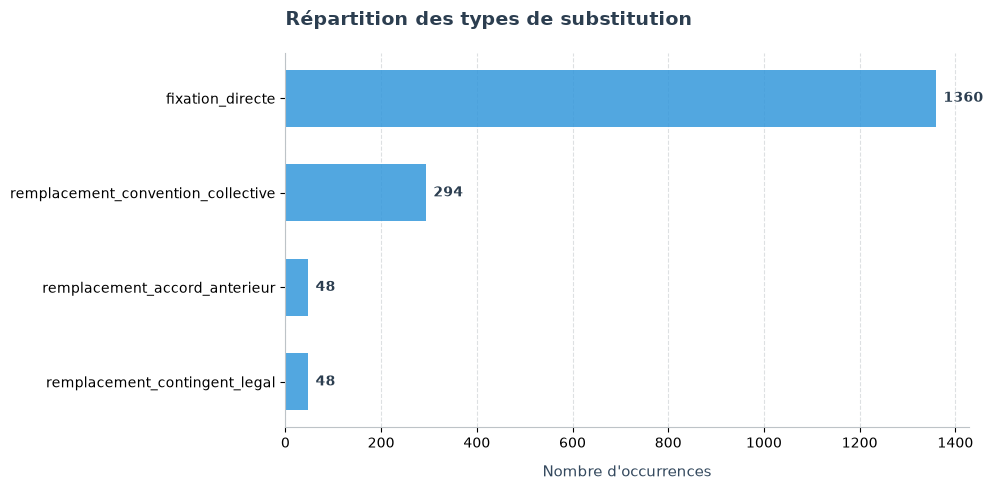

In [18]:
distrib_type_substitution(extraction_developped)

### 2020

In [19]:
extraction, extraction_evo, metadata = fetch_data(2020)

In [20]:
extraction_filtered = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/2745
Nombre d'erreurs dans extraction_evo: 0/2745
Nombre de contingents mesurés dans extraction: 1590
Nombre de contingents mesurés dans extraction_evo: 1545
Nombre d'observations différentes sur la présence d'un contingent: 125
96 observations filtrées:
      - 85 fixent un accord tiré d'un autre texte légal
      - 4 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 7 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
1. D'un commun accord entre les parties signataires, le contingent annuel d'heures supplémentaires est fixé pour l'année 2020 à hauteur de 220 heures par salarié.
2. Par dérogation aux dispositions de l’avenant n°50 du 17 février 2003 étendu par arrêté du 7 juillet 2003 (JO 18 juillet 2003) de la Convention Collective Nationale du Commerce de Détail des fruits, légumes, épicerie et produits laitiers du 15 avril 1988, et conformément aux dispositions de l

In [21]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, ["T03920000784", "T07420003409", "T07420003432", "T20A20000396"])

In [22]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1538
Taille finale : 1597


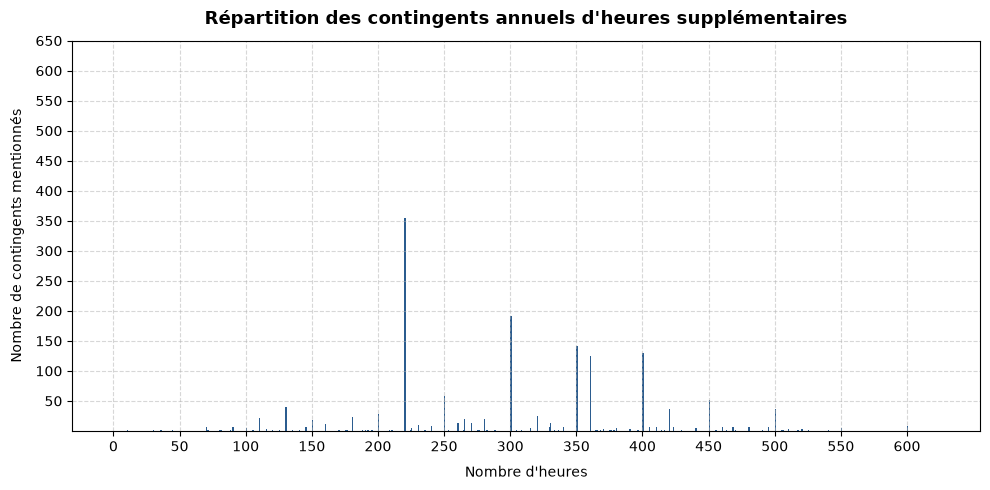

In [23]:
distrib_contingent(extraction_developped)

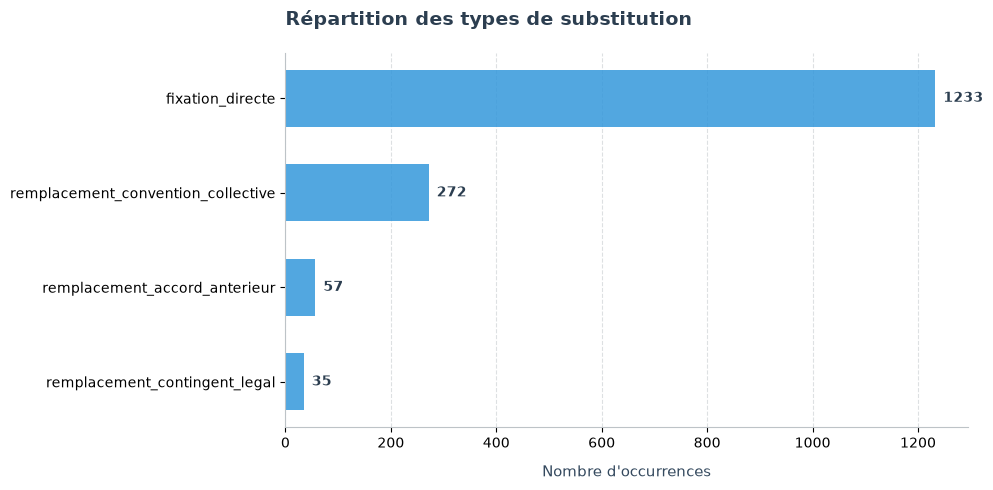

In [24]:
distrib_type_substitution(extraction_developped)

### 2021

In [25]:
extraction, extraction_evo, metadata = fetch_data(2021)

In [26]:
extraction_filtered = treat_extraction(extraction, extraction_evo)

Nombre d'erreurs dans extraction: 0/3057
Nombre d'erreurs dans extraction_evo: 0/3057
Nombre de contingents mesurés dans extraction: 1767
Nombre de contingents mesurés dans extraction_evo: 1772
Nombre d'observations différentes sur la présence d'un contingent: 201
131 observations filtrées:
      - 98 fixent un accord tiré d'un autre texte légal
      - 10 ont une donnée manquante qui a été interprétée comme présente par Qwen
      - 23 rappellent un contingent sans le fixer dans l'accord
      
Citation des extraits supposés anonymisés :
1. Conformément à l'article L.3121-33 du Code du travail, le contingent annuel d'heures supplémentaires est fixé à [blank] heures par salarié sur la période courant du 01er juin N au 31 Mai N+1.
2. Le contingent annuel d’heures supplémentaires librement utilisable est fixé à XXXX heures.
3. Le volume du contingent annuel d'heures est fixé par le présent accord collectif. [...] Cet accord d'entreprise relatif au contingent annuel prime sur l’accord de 

In [31]:
extraction_filtered = add_correct_references(extraction_filtered, extraction_evo, ["T04421012723", "T06921018834", "T07521036147", "T09221024731"])

In [32]:
extraction_developped = develop_contingents(extraction_filtered)

Taille iniale : 1743
Taille finale : 1811


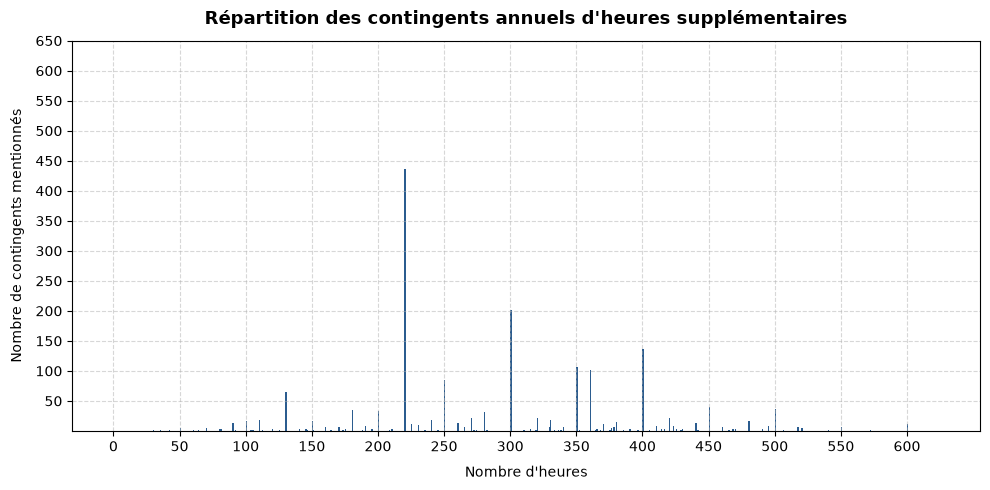

In [33]:
distrib_contingent(extraction_developped)

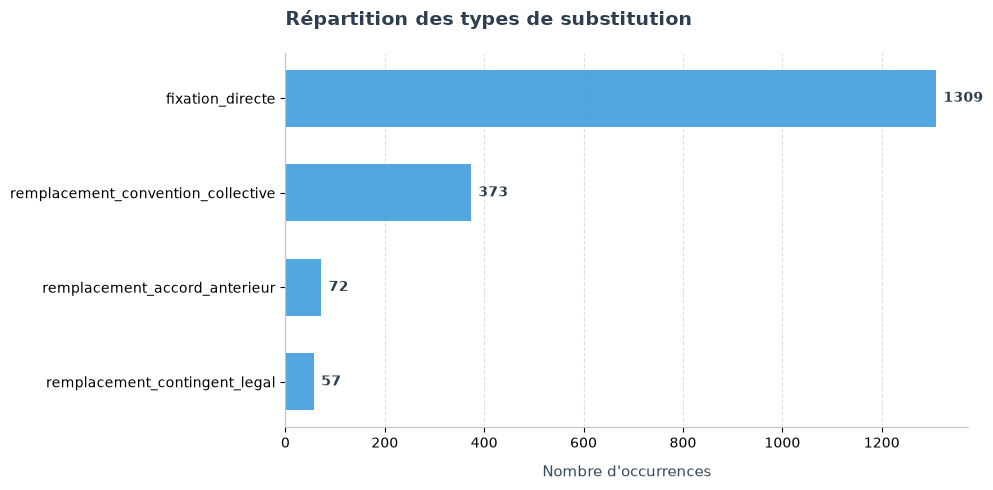

In [34]:
distrib_type_substitution(extraction_developped)